# Constrained matching for crime research

This notebook takes us from separate treatment and offense files to a matched agency panel, before fitting an outcome model. We load the data, clean the records, link the sources, choose comparison agencies, and check how similar the groups are.

**All records are synthetic.** The four input files are included. They illustrate the research design cited at the end; they are not calibrated to real NIBRS data or evidence of a treatment effect.

Run the cells in order from a fresh kernel. The [README](README.md) explains how to get started.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.optimize import Bounds, LinearConstraint, milp

%matplotlib inline

DATA = Path('data')
OUTPUTS = Path('outputs')
DELTA_RAW, DELTA_LOG = 0.035, 0.05
SOLVER_TIME_LIMIT = 600  # Seconds allowed for each optimization pass.
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})


## 1. Load the datasets

The activation list tells us which agencies received treatment and when. The offense file uses agency IDs, so we need a crosswalk to connect the two. The availability table helps us distinguish a missing month from a documented zero.

The example uses three simplified offense labels: `PERS`, `PROP`, and `OTHER`. We first look at a few activation and offense records.


In [2]:
crosswalk = pd.read_csv(DATA / 'crosswalk.csv', dtype={'agency_id': 'string'})
activations = pd.read_csv(DATA / 'activations.csv')
offenses = pd.read_csv(DATA / 'offenses.csv.xz', dtype={
    'agency_id': 'string', 'incident_id': 'string', 'offense_code': 'string',
})
availability = pd.read_csv(DATA / 'availability.csv', dtype={'agency_id': 'string'})
display(activations.head(3), offenses.head(3))


,source_row,agency_name,state,latitude,longitude,activation_date
0,ACT001,synthetic borough 001 pd,ST_B,37.629079,-89.801349,2022-02-15
1,ACT002,synthetic borough 003 pd,ST_A,34.513406,-94.592096,2020-04-15
2,ACT003,synthetic borough 004 pd,ST_A,34.290067,-93.442898,2022-06-15


,agency_id,incident_id,offense_code,incident_date
0,syn0001,0,PERS,2016-01-01
1,syn0001,1,PERS,2016-01-02
2,syn0001,2,PERS,2016-01-03


## 2. Clean the records

We standardize IDs and agency names so that spacing, punctuation, and “PD” do not prevent a link. We also remove invalid offense records and exact duplicates. If the same agency, incident, and offense code have conflicting dates, we set those records aside for review.

An incident can contain several offenses. Keeping the original offense code in the key preserves those distinctions: these are **offense counts**, not incident counts.


In [3]:
CODE_MAP = {'PERS': 'person', 'PROP': 'property', 'OTHER': 'other'}
MONTHS = pd.period_range('2016-01', '2022-12', freq='M').astype(str)

for table in [crosswalk, offenses, availability]:
    table['agency_id'] = table.agency_id.str.strip().str.upper()
for table in [crosswalk, activations]:
    table['name_key'] = (table.agency_name.astype(str).str.upper()
                         .str.replace(r'[^A-Z0-9 ]', ' ', regex=True)
                         .str.replace(r'\bPD\b', 'POLICE DEPARTMENT', regex=True)
                         .str.split().str.join(' '))
assert crosswalk.agency_id.notna().all() and crosswalk.agency_id.is_unique
assert crosswalk[['agency_name', 'state', 'county', 'agency_type']].notna().all().all()
assert np.isfinite(crosswalk[['population', 'latitude', 'longitude']]).all().all()
assert (crosswalk.population.gt(0) & crosswalk.latitude.between(-90, 90)
        & crosswalk.longitude.between(-180, 180)).all()

records = offenses.copy()
records['offense_code'] = records.offense_code.str.strip().str.upper()
records['incident_date'] = pd.to_datetime(records.incident_date, errors='coerce')
valid = (records.agency_id.isin(crosswalk.agency_id)
         & records.incident_date.between('2016-01-01', '2022-12-31')
         & records.offense_code.isin(CODE_MAP) & records.incident_id.notna())
rejected_offenses = records.loc[~valid].copy()
offense_key = ['agency_id', 'incident_id', 'offense_code']
records = records.loc[valid].drop_duplicates(offense_key + ['incident_date'])
conflicting = records.duplicated(offense_key, keep=False)
conflicting_offenses = records.loc[conflicting].copy()
records = records.loc[~conflicting].copy()
records['month'] = records.incident_date.dt.strftime('%Y-%m')
records['outcome'] = records.offense_code.map(CODE_MAP)
print(f'{len(offenses):,} source rows become {len(records):,} retained offense records.')


856,321 source rows become 856,297 retained offense records.


## 3. Link treatment records and build the monthly panel

### Connect agency names to IDs

We accept a name link when it identifies one agency in the same state, within 0.1 degrees in both latitude and longitude, with a valid activation date. Repeated links use the earliest date. Unresolved links remain in `linkage` for review. Agencies sharing an unresolved name-and-state link are excluded from matching.

This is a simple demonstration of linkage. Real treatment records need a reviewed crosswalk, including decisions about uncertain names and locations.


In [4]:
links, uncertain_ids = [], set()
for row in activations.itertuples(index=False):
    same_name = crosswalk.loc[crosswalk.state.eq(row.state) & crosswalk.name_key.eq(row.name_key)]
    nearby = same_name.loc[(same_name.latitude - row.latitude).abs().le(.1)
                           & (same_name.longitude - row.longitude).abs().le(.1)]
    date = pd.to_datetime(row.activation_date, errors='coerce')
    resolved = len(nearby) == 1 and pd.notna(date)
    if not resolved:
        # An uncertain treatment identity must not silently become a comparison.
        uncertain_ids.update(same_name.agency_id)
    links.append({'source_row': row.source_row, 'resolved': resolved,
                  'agency_id': nearby.agency_id.iloc[0] if resolved else pd.NA,
                  'activation_date': date if resolved else pd.NaT})

linkage = pd.DataFrame(links)
linked = linkage.loc[linkage.resolved]
first_activation = linked.groupby('agency_id', as_index=False).activation_date.min()
first_activation['activation_month'] = first_activation.activation_date.dt.strftime('%Y-%m')
metadata = crosswalk.drop(columns='name_key').merge(
    first_activation, on='agency_id', how='left', validate='one_to_one',
)
metadata['linkage_uncertain'] = metadata.agency_id.isin(uncertain_ids)
metadata['treatment_status'] = np.where(metadata.activation_month.notna(),
                                       'recorded_activation', 'no_recorded_activation')
metadata.loc[metadata.linkage_uncertain, 'treatment_status'] = 'unresolved_linkage'
print(f'{len(linked)} of {len(linkage)} activation rows linked; '
      f'{len(linkage) - len(linked)} unresolved.')


86 of 87 activation rows linked; 1 unresolved.


### Count offenses and merge the sources

We count offenses by agency and month, then attach activation dates. A missing agency-month stays missing unless the availability table documents an all-offense zero. The [FBI's NIBRS manual](https://le.fbi.gov/file-repository/nibrs-user-manual-2025-0-062625.pdf) distinguishes zero reports from absent submissions (§3.3).

To follow this study's sample rule, an agency must have at least one retained offense record in **every month from January 2016 through December 2022**, with no unresolved treatment identity. Even a documented all-offense zero fails this particular screen. A category zero is allowed when other offenses are present. This is a study-specific source-presence rule, not a general definition of complete NIBRS reporting.


In [5]:
monthly = records.groupby(['agency_id', 'month', 'outcome']).size().unstack(fill_value=0)
monthly = monthly.reindex(columns=['person', 'property', 'other'], fill_value=0).reset_index()
monthly.columns.name = None
monthly['all'] = monthly[['person', 'property', 'other']].sum(axis=1)
monthly['source_present'] = True

grid = pd.MultiIndex.from_product([metadata.agency_id, MONTHS],
                                 names=['agency_id', 'month']).to_frame(index=False)
panel = grid.merge(monthly, on=['agency_id', 'month'], how='left', validate='one_to_one')
panel = panel.merge(availability, on=['agency_id', 'month'], how='left', validate='one_to_one')
for column in ['source_present', 'report_received', 'verified_zero']:
    panel[column] = panel[column].eq(True)
assert not (panel.verified_zero & panel.source_present).any(), 'Conflicting zero report.'
panel.loc[panel.verified_zero, ['all', 'person', 'property', 'other']] = 0
metadata['source_months'] = metadata.agency_id.map(panel.groupby('agency_id').source_present.sum())
metadata['source_eligible'] = metadata.source_months.eq(len(MONTHS)) & ~metadata.linkage_uncertain

panel = panel.merge(metadata[['agency_id', 'activation_month', 'treatment_status']],
                    on='agency_id', how='left', validate='many_to_one')
assert len(panel) == len(grid) and not panel.duplicated(['agency_id', 'month']).any()
display(panel.loc[panel.activation_month.notna(),
                  ['agency_id', 'month', 'all', 'person', 'property', 'activation_month']].head(4))
print(f'{len(panel):,} agency-months joined; '
      f'{metadata.source_eligible.sum()} of {len(metadata)} agencies pass the sample screen.')


20,496 agency-months joined; 242 of 244 agencies pass the sample screen.


,agency_id,month,all,person,property,activation_month
0,SYN0001,2016-01,44.0,8.0,25.0,2022-02
1,SYN0001,2016-02,78.0,9.0,55.0,2022-02
2,SYN0001,2016-03,79.0,19.0,46.0,2022-02
3,SYN0001,2016-04,83.0,12.0,60.0,2022-02


## 4. Match agencies

### Summarize the pretreatment histories

For each treatment month, we summarize the preceding 24 months for every eligible agency. The seven characteristics are population, mean monthly counts, and fitted monthly trends for all, person, and property offenses. Each trend is the slope of a straight line through the monthly counts.

We also keep transformed versions. For population and mean counts, we use `log(1 + value)`. For trends, we first transform each month's count and then calculate the slope. Both agencies in a candidate pair use the **same calendar months**.


In [6]:
OUTCOMES = ["all", "person", "property"]
RAW_FEATURES = ["population", "mean_all", "mean_person", "mean_property",
                "slope_all", "slope_person", "slope_property"]
LOG_FEATURES = ["log_" + name for name in RAW_FEATURES]
FEATURE_NAMES = RAW_FEATURES + LOG_FEATURES
EDGE_KEYS = ["treated_id", "comparison_id", "activation_month", "activation_year"]
DELTA_COLUMNS = [f"delta_{scale}_{name}" for scale in ("raw", "log") for name in RAW_FEATURES]

def feature_values(feature_index, ids, anchors, columns):
    keys = pd.MultiIndex.from_arrays([list(ids), list(anchors)], names=["agency_id", "anchor_month"])
    return feature_index.loc[keys, columns].to_numpy(float)

eligible = metadata.loc[metadata.source_eligible].copy()
eligible["activation_month"] = eligible.activation_month.astype("string")
treated = eligible.loc[eligible.activation_month.between("2019-01", "2022-12").fillna(False)]
controls = eligible.loc[eligible.activation_month.isna() | (eligible.activation_month > "2022-12")]
controls = controls.reset_index(drop=True)
counts = panel.set_index(["agency_id", "month"])

time = np.arange(24, dtype=float) - 11.5
feature_rows = []
for anchor in sorted(treated.activation_month.unique()):
    months = pd.period_range(pd.Period(anchor, "M") - 24, periods=24).astype(str)
    for agency in eligible.itertuples(index=False):
        keys = pd.MultiIndex.from_product([[agency.agency_id], months])
        values = counts.reindex(keys)[OUTCOMES].to_numpy(float)
        if not np.isfinite(values).all() or (values < 0).any():
            raise ValueError(f"Incomplete or invalid preperiod: {agency.agency_id}, {anchor}")
        means = values.mean(axis=0)
        slopes = time @ values / (time @ time)
        log_slopes = time @ np.log1p(values) / (time @ time)
        raw = np.r_[agency.population, means, slopes]
        transformed = np.r_[np.log1p(raw[:4]), log_slopes]
        feature_rows.append([agency.agency_id, anchor, *raw, *transformed])

features = pd.DataFrame(feature_rows, columns=["agency_id", "anchor_month"] + FEATURE_NAMES)
feature_index = features.set_index(["agency_id", "anchor_month"])
print(f"{len(features):,} agency-window records prepared from the 24 pretreatment months.")


9,680 agency-window records prepared from the 24 pretreatment months.


### Narrow the comparison pool

Crime-domain considerations come before the optimizer. These restrictions follow the study design; the numerical cutoffs are choices for this application.

| Rule | Reason |
| --- | --- |
| No comparison activation recorded through December 2022 | Keep comparisons outside the recorded treatment group throughout the study period. |
| Same state and agency type | Compare agencies in a common state context with similar institutional roles. |
| Different counties and coordinates | Reduce the chance of comparing agencies that serve overlapping areas. |
| No more than 250 miles apart | Keep comparisons reasonably close geographically. |
| Population ratio no greater than 3:1 | Avoid large size differences when matching on offense counts. |
| Standardized distance no greater than four | Remove pairs whose population and crime histories are too dissimilar. |

Police departments and sheriffs' offices differ in their jurisdictions and roles ([BJS](https://bjs.ojp.gov/topics/law-enforcement/agency-characteristics)). County and coordinate screens do **not** guarantee separate jurisdictions or rule out spillovers: the [FBI](https://le.fbi.gov/file-repository/nibrs-user-manual-2025-0-062625.pdf) describes overlapping reporting jurisdictions (§1.4), and [Census](https://www.census.gov/programs-surveys/popest/about/glossary/geo-terms.html) notes that municipalities can cross county boundaries.

Distance combines differences in the seven transformed characteristics after dividing each by a standard deviation. For these SDs, we use all source-eligible agencies at that treatment month, including agencies treated before 2019. We clip values at the 1st and 99th percentiles **only when calculating the SDs**; pair differences use the original values. The code uses sample SDs and linearly interpolated percentiles.


In [7]:
candidate_frames = []
control_latitudes = np.radians(controls.latitude.to_numpy())
control_longitudes = np.radians(controls.longitude.to_numpy())
control_populations = controls.population.to_numpy()

for anchor, group in treated.groupby("activation_month", sort=True):
    window = feature_index.xs(anchor, level="anchor_month")
    pool = window.loc[eligible.agency_id, LOG_FEATURES].to_numpy(float)
    low, high = np.quantile(pool, [.01, .99], axis=0, method="linear")
    scales = np.clip(pool, low, high).std(axis=0, ddof=1)
    if not np.isfinite(scales).all() or (scales <= 0).any():
        raise ValueError(f"Undefined or zero distance SD at {anchor}.")
    control_values = window.loc[controls.agency_id, FEATURE_NAMES].to_numpy(float)

    for agency in group.itertuples(index=False):
        treated_values = window.loc[agency.agency_id, FEATURE_NAMES].to_numpy(float)
        differences = treated_values - control_values
        distance = np.sqrt(((differences[:, len(RAW_FEATURES):] / scales) ** 2).sum(axis=1))
        latitude = np.radians(agency.latitude)
        longitude_gap = control_longitudes - np.radians(agency.longitude)
        h = (np.sin((control_latitudes - latitude) / 2) ** 2
             + np.cos(latitude) * np.cos(control_latitudes) * np.sin(longitude_gap / 2) ** 2)
        miles = 2 * 3958.7613 * np.arcsin(np.sqrt(np.clip(h, 0, 1)))
        population_ratio = np.maximum(agency.population / control_populations,
                                      control_populations / agency.population)
        allowed = (controls.state.eq(agency.state)
                   & controls.agency_type.eq(agency.agency_type)
                   & controls.county.ne(agency.county)
                   & (controls.latitude.ne(agency.latitude) | controls.longitude.ne(agency.longitude))
                   & (miles <= 250) & (population_ratio <= 3) & (distance <= 4))
        candidates = pd.DataFrame({"treated_id": agency.agency_id,
            "comparison_id": controls.agency_id.to_numpy(), "activation_month": anchor,
            "activation_year": int(anchor[:4]), "geo_miles": miles,
            "population_ratio": population_ratio, "distance": distance})
        candidates[DELTA_COLUMNS] = differences
        candidate_frames.append(candidates.loc[allowed])

columns = EDGE_KEYS + ["geo_miles", "population_ratio", "distance"] + DELTA_COLUMNS
edges = pd.concat(candidate_frames, ignore_index=True) if candidate_frames else pd.DataFrame(columns=columns)
if edges.empty:
    raise ValueError("No candidate pairs meet the eligibility rules. Review the inputs and design.")
assert not edges.duplicated(EDGE_KEYS).any()
print(f"{len(edges):,} eligible candidate pairs for {edges.treated_id.nunique()} treated agencies.")


1,630 eligible candidate pairs for 79 treated agencies.


### Choose the pairs

We match separately for each activation year. Within a year, each treated agency gets at most one comparison, and each comparison can be used once. Comparisons can be reused in another year.

The optimizer first retains as many pairs as the rules allow. It then holds that number fixed and chooses the pairs with the smallest total distance. The selected groups must satisfy all fourteen mean-balance limits: **0.035 reference SDs for each raw characteristic** and **0.05 for each transformed characteristic**. These reference SDs are calculated once per year from the distinct treated agencies with candidates, each at its own activation month. They are separate from the distance SDs above.

The matrix below gives each candidate pair a column. The assignment rows limit each agency to one match. The balance rows enforce `abs(sum of standardized differences) <= tolerance × number of pairs`. Subtracting the tolerance from each difference puts this rule into the linear form the solver needs. Both optimization passes must reach an optimal solution before we continue.


In [8]:
tolerance = np.array([DELTA_RAW] * len(RAW_FEATURES) + [DELTA_LOG] * len(LOG_FEATURES))
if (not np.isfinite(tolerance).all() or (tolerance < 0).any()
        or not np.isfinite(SOLVER_TIME_LIMIT) or SOLVER_TIME_LIMIT <= 0):
    raise ValueError("Use nonnegative balance limits and a positive solver time limit.")

selected, solver_rows = [], []
for year, group in edges.groupby("activation_year", sort=True):
    group = group.sort_values(EDGE_KEYS).reset_index(drop=True)
    anchors = group[["treated_id", "activation_month"]].drop_duplicates()
    if len(anchors) < 2:
        raise ValueError(f"Year {year}: at least two matchable treated agencies are needed.")
    treated_values = feature_values(
        feature_index, anchors.treated_id, anchors.activation_month, FEATURE_NAMES
    )
    sd = treated_values.std(axis=0, ddof=1)
    if not np.isfinite(sd).all() or (sd <= 0).any():
        raise ValueError(f"Year {year}: the reference SDs must be finite and positive.")

    # One row per agency and one column per candidate pair.
    assignments = pd.get_dummies(
        group[["treated_id", "comparison_id"]], dtype=float
    ).to_numpy().T
    difference = group[DELTA_COLUMNS].to_numpy(float).T / sd[:, None]
    matrix = np.vstack([
        assignments, difference - tolerance[:, None], -difference - tolerance[:, None]
    ])
    upper = np.r_[np.ones(len(assignments)), np.zeros(2 * len(tolerance))]
    constraints = [LinearConstraint(matrix, -np.inf, upper)]

    for stage, objective in [
        ("cardinality", -np.ones(len(group))),
        ("distance", group.distance.to_numpy(float)),
    ]:
        result = milp(
            c=objective, integrality=np.ones(len(group)), bounds=Bounds(0, 1),
            constraints=constraints,
            options={"time_limit": SOLVER_TIME_LIMIT, "mip_rel_gap": 0.0},
        )
        if result.status != 0 or result.x is None or not np.isfinite(result.x).all():
            raise RuntimeError(f"Year {year}, {stage}: no valid optimal solution. {result.message}")
        keep = np.rint(result.x).astype(int)
        if (np.max(np.abs(result.x - keep)) > 1e-6
                or (keep < 0).any() or (keep > 1).any()
                or (matrix @ keep > upper + 1e-6).any()):
            raise AssertionError(f"Year {year}, {stage}: the selected pairs failed a constraint.")
        solver_rows.append({
            "activation_year": year, "pass": stage, "status": result.status,
            "n_matches": int(keep.sum()), "objective": result.fun, "gap": result.mip_gap,
        })
        if stage == "cardinality":
            maximum = int(keep.sum())
            # The distance pass must keep this many pairs.
            constraints.append(LinearConstraint(np.ones((1, len(group))), maximum, maximum))
        elif keep.sum() != maximum:
            raise AssertionError(f"Year {year}: the distance pass changed the pair count.")
    selected.append(group.loc[keep == 1].copy())

matches = pd.concat(selected, ignore_index=True)
solver_log = pd.DataFrame(solver_rows)


In [9]:
treated = treated.copy()
treated["activation_year"] = treated.activation_month.str[:4].astype(int)
treated["has_candidates"] = treated.agency_id.isin(edges.treated_id)
treated["matched"] = treated.agency_id.isin(matches.treated_id)
retention = treated.groupby("activation_year").agg(
    eligible_treated=("agency_id", "size"), with_candidates=("has_candidates", "sum"),
    matched=("matched", "sum"),
)
display(retention.rename(columns={
    "eligible_treated": "Eligible treated", "with_candidates": "With candidates", "matched": "Matched"
}).rename_axis("Activation year"))
print(f"{len(matches)} pairs selected; all {len(solver_log)} solver passes reached optimal status.")


79 pairs selected; all 8 solver passes reached optimal status.


,Eligible treated,With candidates,Matched
Activation year,,,
2019,21,19,19
2020,21,20,20
2021,21,20,20
2022,21,20,20


## 5. Check the matches

### Balance before and after matching

Before matching, each treated agency with an eligible candidate gets equal weight, and we share its comparison weight equally among its candidates. After matching, each selected pair gets equal weight. The reference SDs stay fixed. Agencies without candidates appear in the retention table above but are not part of this comparison.

Each panel below shows one activation year. Points closer to zero mean more similar group averages; the dashed line marks the raw balance limit. A gap of 0.10 means one tenth of a reference SD. The figure shows the seven raw characteristics, and the code checks all raw and transformed limits directly from the selected agencies' features.


All 56 annual feature-balance checks passed.


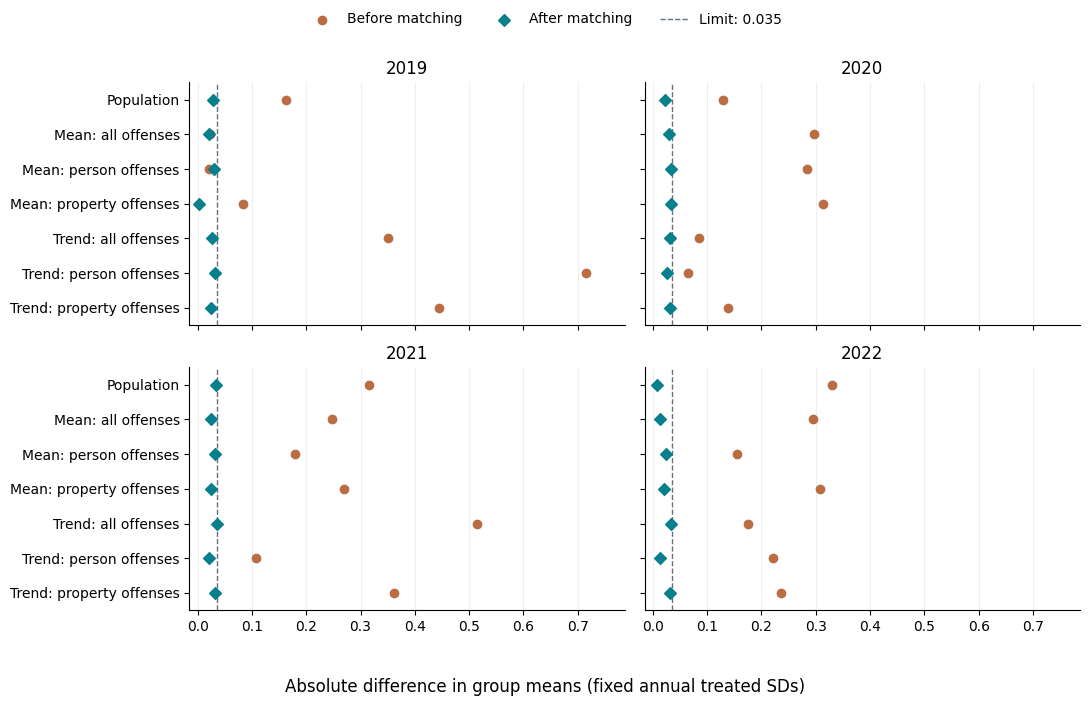

In [10]:
def balance_report(selected):
    # Keep the same reference agencies and SDs when checking a smaller sample later.
    rows = []
    for year, candidates in edges.groupby('activation_year'):
        anchors = candidates[['treated_id', 'activation_month']].drop_duplicates()
        before_t = feature_values(feature_index, anchors.treated_id,
                                  anchors.activation_month, FEATURE_NAMES)
        candidate_c = feature_values(feature_index, candidates.comparison_id,
                                     candidates.activation_month, FEATURE_NAMES)
        before_c = pd.DataFrame(candidate_c, index=candidates.treated_id).groupby(level=0).mean()
        chosen = selected.loc[selected.activation_year.eq(year)]
        after_t = feature_values(feature_index, chosen.treated_id, chosen.activation_month, FEATURE_NAMES)
        after_c = feature_values(feature_index, chosen.comparison_id, chosen.activation_month, FEATURE_NAMES)
        sd = before_t.std(axis=0, ddof=1)
        before = (before_t.mean(axis=0) - before_c.mean(axis=0).to_numpy()) / sd
        after = ((after_t.mean(axis=0) - after_c.mean(axis=0)) / sd
                 if len(chosen) else np.full(len(FEATURE_NAMES), np.nan))
        rows.append(pd.DataFrame({
            'activation_year': year, 'representation': ['raw'] * 7 + ['log'] * 7,
            'feature': RAW_FEATURES * 2, 'before': before, 'after': after,
            'limit': [DELTA_RAW] * 7 + [DELTA_LOG] * 7,
        }))
    return pd.concat(rows, ignore_index=True)

balance = balance_report(matches)
assert balance.after.notna().all() and (balance.after.abs() <= balance.limit + 1e-7).all()
print(f'All {len(balance)} annual feature-balance checks passed.')

labels = ['Population', 'Mean: all offenses', 'Mean: person offenses', 'Mean: property offenses',
          'Trend: all offenses', 'Trend: person offenses', 'Trend: property offenses']
raw_balance = balance.loc[balance.representation.eq('raw')]
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True, sharey=True)
for ax, (year, group) in zip(axes.flat, raw_balance.groupby('activation_year')):
    gaps = group.set_index('feature').loc[RAW_FEATURES, ['before', 'after']].abs()
    for stage, marker, color in [('before', 'o', '#BA6D43'), ('after', 'D', '#087F8C')]:
        ax.scatter(gaps[stage], np.arange(7), marker=marker, color=color, s=36,
                   label=f'{stage.capitalize()} matching', zorder=3)
    ax.axvline(DELTA_RAW, color='#637282', ls='--', lw=1, label=f'Limit: {DELTA_RAW}')
    ax.set(title=str(year), yticks=np.arange(7), yticklabels=labels, ylim=(6.5, -.5))
    ax.grid(axis='x', alpha=.2)
axes[0, 0].set_xlim(-.015, raw_balance[['before', 'after']].abs().to_numpy().max() * 1.1)
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc='upper center', ncol=3, frameon=False)
fig.supxlabel('Absolute difference in group means (fixed annual treated SDs)')
fig.tight_layout(rect=(0, .03, 1, .94))
plt.show()


### Look at the monthly histories

This figure shows property-offense counts for the 2019 activation cohort. Thin lines are monthly group averages; thick lines are fitted linear trends. **Both panels use pretreatment data.** “After” means after matching, not after treatment. The group weights are the same as in the balance check.

The small table summarizes differences in average levels and slopes. These are characteristics used to choose matches; matching does not try to make every month's count identical.


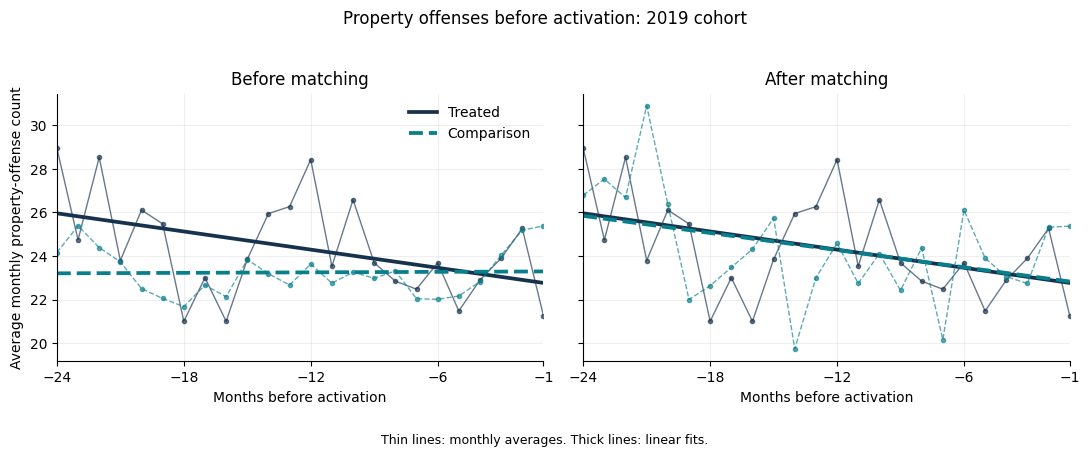

,Before,After
Gap in 24-month mean (offenses),1.1144,0.0263
Gap in slope (offenses per month),0.1427,0.0080


In [11]:
HISTORY_YEAR = 2019
event_months = np.arange(-24, 0)
centered_months = event_months - event_months.mean()
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)
history_metrics = {}

for ax, stage, sample in zip(axes, ['Before', 'After'], [edges, matches]):
    cohort = sample.loc[sample.activation_year.eq(HISTORY_YEAR)]
    averages, slopes = {}, {}
    for role, color, style in [('Treated', '#17324D', '-'), ('Comparison', '#087F8C', '--')]:
        histories = []
        for treated_id, group in cohort.groupby('treated_id'):
            anchor = pd.Period(group.activation_month.iloc[0], freq='M')
            months = pd.period_range(anchor - 24, periods=24, freq='M').astype(str)
            agencies = [treated_id] if role == 'Treated' else group.comparison_id.tolist()
            keys = pd.MultiIndex.from_product([agencies, months], names=['agency_id', 'month'])
            values = counts.loc[keys, 'property'].to_numpy().reshape(len(agencies), 24)
            histories.append(values.mean(axis=0))
        values = np.mean(histories, axis=0)
        slope = centered_months @ values / (centered_months @ centered_months)
        averages[role], slopes[role] = values.mean(), slope
        ax.plot(event_months, values, color=color, ls=style, marker='o', ms=3, lw=1, alpha=.65)
        ax.plot(event_months, values.mean() + slope * centered_months,
                color=color, ls=style, lw=2.7, label=role)
    history_metrics[stage] = [abs(averages['Treated'] - averages['Comparison']),
                              abs(slopes['Treated'] - slopes['Comparison'])]
    ax.set(title=f'{stage} matching', xlabel='Months before activation',
           xticks=[-24, -18, -12, -6, -1], xlim=(-24, -1))
    ax.grid(alpha=.2)
axes[0].set_ylabel('Average monthly property-offense count')
axes[0].legend(frameon=False)
fig.suptitle(f'Property offenses before activation: {HISTORY_YEAR} cohort')
fig.text(.5, .015, 'Thin lines: monthly averages. Thick lines: linear fits.', ha='center', fontsize=9)
fig.tight_layout(rect=(0, .07, 1, .95))
plt.show()
history_metrics = pd.DataFrame(history_metrics, index=[
    'Gap in 24-month mean (offenses)', 'Gap in slope (offenses per month)',
])
display(history_metrics.round(4))


Read the monthly paths alongside the summaries: similar average levels and fitted slopes can still leave differences in timing and shape. Before matching, the comparison curve averages multiple candidates per treated agency; afterward, it uses the selected comparisons.

For a later difference-in-differences analysis, this is a descriptive check of observed histories. Parallel trends concerns how outcomes would have changed **without treatment**. Balance on features used to select matches cannot establish that assumption, and unequal monthly fluctuations alone do not establish a violation. Persistent differences in trend or shape deserve attention before model fitting. See [Callaway and Sant'Anna (2021)](https://doi.org/10.1016/j.jeconom.2020.12.001) and [Roth (2022)](https://doi.org/10.1257/aeri.20210236).


### Save the matched panels and check follow-up

We keep both agencies in each pair for all 84 months. We also prepare the study's analysis window: 24 months before activation and six months of follow-up, including the activation month. With data ending in December 2022, this retains activations through July 2022.

We apply this follow-up restriction **after matching, without choosing new pairs**. Because dropping pairs can change balance, we check the smaller sample using the original reference SDs. Pair IDs distinguish assignments when a comparison is reused across years.


In [12]:
pairs = matches[EDGE_KEYS + ['distance']].sort_values(
    ['activation_year', 'treated_id']).reset_index(drop=True)
pairs.insert(0, 'pair_id', [f'PAIR_{i + 1:04d}' for i in range(len(pairs))])
pairs['complete_six_month_followup'] = pairs.activation_month.le('2022-07')
roles = pd.concat([
    pairs.assign(agency_id=pairs[id_column], role=role)[
        ['pair_id', 'agency_id', 'role', 'activation_month', 'activation_year']]
    for role, id_column in [('treated', 'treated_id'), ('comparison', 'comparison_id')]
], ignore_index=True)
count_columns = ['agency_id', 'month', 'all', 'person', 'property', 'other', 'source_present']
matched_panel = roles.merge(panel[count_columns], on='agency_id', how='left')
assert len(matched_panel) == len(pairs) * 2 * len(MONTHS) and matched_panel.source_present.all()
matched_panel['event_month'] = (pd.PeriodIndex(matched_panel.month, freq='M').asi8
                               - pd.PeriodIndex(matched_panel.activation_month, freq='M').asi8)
matched_panel['is_treated'] = matched_panel.role.eq('treated').astype(int)
matched_panel['is_post'] = matched_panel.event_month.ge(0).astype(int)
primary_pairs = pairs.loc[pairs.complete_six_month_followup].copy()
primary_panel = matched_panel.loc[
    matched_panel.pair_id.isin(primary_pairs.pair_id) & matched_panel.event_month.between(-24, 5)
].copy()
assert len(primary_panel) == len(primary_pairs) * 2 * 30

primary_balance = balance_report(primary_pairs)
remaining_gaps = primary_balance.assign(gap=primary_balance.after.abs()).pivot_table(
    index='activation_year', columns='representation', values='gap', aggfunc='max'
).reindex(index=sorted(edges.activation_year.unique()), columns=['raw', 'log'])
remaining_gaps['Within original limits'] = (remaining_gaps.raw.le(DELTA_RAW + 1e-7)
                                           & remaining_gaps.log.le(DELTA_LOG + 1e-7))
retained_counts = primary_pairs.groupby('activation_year').size().reindex(remaining_gaps.index, fill_value=0)
remaining_gaps.insert(0, 'Pairs retained', retained_counts)
display(remaining_gaps.rename(columns={'raw': 'Largest raw gap', 'log': 'Largest transformed gap'})
        .rename_axis('Activation year').rename_axis(columns=None).round(4))
if not remaining_gaps['Within original limits'].all():
    print('The follow-up sample exceeds the original balance limits. Resolve this before model fitting.')

OUTPUTS.mkdir(exist_ok=True)
pairs.to_csv(OUTPUTS / 'matched_pairs.csv', index=False)
matched_panel.to_csv(OUTPUTS / 'matched_panel_full.csv', index=False)
primary_panel.to_csv(OUTPUTS / 'matched_panel_primary_window.csv', index=False)
balance.to_csv(OUTPUTS / 'balance_before_after.csv', index=False)
primary_balance.to_csv(OUTPUTS / 'balance_after_followup_filter.csv', index=False)
print(f'Saved {len(pairs)} matched pairs, two panels, and two balance tables in outputs/. '
      f'{len(primary_pairs)} pairs have complete follow-up.')


The follow-up sample exceeds the original balance limits. Resolve this before model fitting.
Saved 79 matched pairs, two panels, and two balance tables in outputs/. 74 pairs have complete follow-up.


,Pairs retained,Largest raw gap,Largest transformed gap,Within original limits
Activation year,,,,
2019,19,0.0318,0.0452,True
2020,20,0.0330,0.0495,True
2021,20,0.0348,0.0497,True
2022,15,0.2133,0.3058,False


The follow-up table tells us whether the smaller sample still meets the original limits. Passing the full-sample check does not guarantee that a later subset will pass. Restricting eligibility to complete-follow-up agencies before matching would change this design. The workflow stops here, before outcome-model fitting.

## Using your own data

Adapt sections 1–3 to produce the two tables below, then continue with matching. Keep agency IDs as strings and months in `YYYY-MM` format.

| Table | Required information |
| --- | --- |
| `metadata` | One row per `agency_id`: `state`, `county`, `agency_type`, `latitude`, `longitude`, positive `population`, `activation_month`, and `source_eligible` |
| `panel` | One row per agency and month: `all`, `person`, `property`, `other`, and `source_present`, covering January 2016–December 2022 |

Recalculate eligibility from the study's source-presence rule and reviewed treatment identities. Unknown treatment status must not become “no activation.” Observed counts should be nonnegative integers, with the categories adding to `all`. Keep missing counts distinct from documented zeros. Retain eligible agencies treated before 2019: they contribute to distance SDs even though they enter neither assignment group.

Real NIBRS records need a complete offense-code mapping and a documented incident/report-date convention. Preserve the original agency/incident/offense-code key; include year if incident IDs repeat across years. Review jurisdiction boundaries and reporting agreements as well as agency links. Record source versions and the population reference year; this study uses the 2012 LEAIC population as a fixed size characteristic, rather than converting counts to rates.

### Method reference

Delos Santos, C. (2026). *Applied Mathematical Modeling of Risk and Mitigation in the Context of Crime, Digital Policing, and Natural Hazards*. Doctoral dissertation, Arizona State University, pp. 58–71.

The original study reported a weighted objective, `−pair_count + 1e−5 × total_distance`, with a relative solver gap of `1e−6`. This notebook implements the cardinality-first priority in two passes and requests a zero relative gap through [SciPy's `milp`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.milp.html). It is a reconstruction of the procedure, not the original software environment.
